# 03 Task 3: network sectorization
**Problem.** Given $G=(V,E)$ with pipe lengths $\ell$ (task 2) and sources $S\subseteq V$, assign every node to its closest source by network distance,
$$\sigma(v)=\arg\min_{s\in S} d_G(s,v),$$
and list the pipes that must be closed to separate the sectors: $C=\{(u,v)\in E:\sigma(u)\ne\sigma(v)\}$.

**Input:** the instance and the pipe lengths. **Output:** the sector of every node, the closed pipes, and a colour-coded map.

**Technique: greedy shortest paths (Dijkstra).** All lengths are non-negative, so Dijkstra's greedy rule (permanently settle the closest unsettled node) is exact. Two variants are compared: Dijkstra repeated from each source followed by an argmin per node, and a single multi-source Dijkstra that starts with every source in the heap at distance 0. Multi-source Dijkstra is equivalent to adding a virtual super-source joined to every source by a zero-length pipe; each node is settled by whichever source reaches it first, which is exactly $\sigma(v)$.

$C$ is both necessary and sufficient: any open inter-sector pipe would join two sectors, and once all of them are closed no pipe leaves a sector.

In [1]:
import os, sys
if 'google.colab' in sys.modules and not os.path.isdir('../water'):
    os.system('git clone -q https://github.com/santihdzs/water-distribution')
    os.chdir('water-distribution/notebooks')
sys.path.insert(0, os.path.abspath('..'))

import inspect
import matplotlib.pyplot as plt
import networkx as nx
import water
from water import graph, paths, plot, tasks

plot.setup()
nets = water.load_all()

In [2]:
print(inspect.getsource(paths.multi_source_dijkstra))
print(inspect.getsource(tasks.sectorize))

def multi_source_dijkstra(adj, sources):
    """all sources start in the heap at distance 0; each node keeps the source that reached it first."""
    rank = {s: k for k, s in enumerate(sources)}
    dist = {s: 0.0 for s in sources}
    origin = {s: s for s in sources}
    parent = {s: None for s in sources}
    done, heap = set(), [(0.0, rank[s], s) for s in sources]
    heapq.heapify(heap)
    pops = relax = 0
    while heap:
        d, r, u = heapq.heappop(heap)
        pops += 1
        if u in done:
            continue
        done.add(u)
        for v, w in adj[u]:
            relax += 1
            nd = d + w
            # rank breaks exact distance ties the same way repeated_dijkstra does
            if (nd, r) < (dist.get(v, math.inf), rank[origin[v]] if v in origin else math.inf):
                dist[v], origin[v], parent[v] = nd, origin[u], u
                heapq.heappush(heap, (nd, r, v))
    return dist, origin, parent, {'pops': pops, 'relaxations': relax}

def sectorize

## Correctness
1. Repeated and multi-source Dijkstra give the same assignment and distances, and both match `networkx.multi_source_dijkstra`.
2. Exact ties (a node equidistant from two sources) are counted; both variants break them in favour of the earlier source.
3. After closing $C$, the components found with the task 1 BFS are exactly the sectors, one source each.
4. Closing $C$ does not lengthen any node's route to its own source: Dijkstra on each closed sector reproduces the distances. This holds because every node on a shortest path from $s$ to $v\in$ sector($s$) is itself closer to $s$ than to any other source.

In [3]:
secs = {}
for name, net in nets.items():
    adj = graph.adjacency_list(net)
    sec = tasks.sectorize(net)
    dist_r, origin_r, _, runs, stats_r = paths.repeated_dijkstra(adj, net.sources)
    assert origin_r == sec['origin'] and all(abs(dist_r[u] - sec['dist'][u]) < 1e-9 for u in adj)
    G = nx.Graph(); G.add_weighted_edges_from((u, v, net.length(u, v)) for u, v, _ in net.pipes)
    ref = nx.multi_source_dijkstra_path_length(G, net.sources)
    assert all(abs(ref[u] - sec['dist'][u]) < 1e-9 for u in adj)
    ties = [u for u in adj if abs(runs[0][0][u] - runs[1][0][u]) < 1e-9]

    comps = graph.components(graph.adjacency_list(net, sec['kept']))
    assert sorted(comps) == sorted(sec['members'].values())
    for s, members in sec['members'].items():
        d, *_ = paths.dijkstra(graph.adjacency_list(net, [p for p in sec['kept'] if sec['origin'][p[0]] == s]), s)
        assert all(abs(d[u] - sec['dist'][u]) < 1e-9 for u in members)
    secs[name] = sec
    print(f'{name}: checks passed, {len(ties)} exact ties | heap pops repeated {stats_r["pops"]} vs multi '
          f'{sec["stats"]["pops"]}, relaxations {stats_r["relaxations"]} vs {sec["stats"]["relaxations"]}')

NYT: checks passed, 0 exact ties | heap pops repeated 40 vs multi 21, relaxations 84 vs 42
HAN: checks passed, 0 exact ties | heap pops repeated 65 vs multi 32, relaxations 136 vs 68
FOS: checks passed, 0 exact ties | heap pops repeated 88 vs multi 43, relaxations 232 vs 116
PES: checks passed, 0 exact ties | heap pops repeated 155 vs multi 76, relaxations 392 vs 196


Multi-source Dijkstra does the work of one Dijkstra run regardless of the number of sources: with $|S|=2$ it performs exactly half the relaxations and about half the heap pops of the repeated variant. Measured times are in `08_performance`.

## Results

In [4]:
rows = []
for name, net in nets.items():
    sec = secs[name]
    for s, members in sec['members'].items():
        print(f'{name} sector of source {s} ({len(members)} nodes): {members}')
    closed = ', '.join(f'{u}-{v}' for u, v, _ in sec['closed'])
    print(f'{name} pipes to close ({len(sec["closed"])} of {len(net.pipes)}): {closed}\n')
    rows.append([name, ', '.join(f'{s}: {len(m)}' for s, m in sec['members'].items()),
                 len(sec['closed']), closed])

plot.table('sectors', rows, ['Inst.', 'Source: nodes', r'$|C|$', 'Pipes to close'], ['{}', '{}', '{}', '{}'])

NYT sector of source 17 (10 nodes): [3, 4, 5, 6, 7, 8, 9, 10, 16, 17]
NYT sector of source 19 (10 nodes): [1, 2, 11, 12, 13, 14, 15, 18, 19, 20]
NYT pipes to close (3 of 21): 2-3, 11-9, 20-16

HAN sector of source 13 (7 nodes): [8, 9, 10, 11, 12, 13, 14]
HAN sector of source 1 (25 nodes): [1, 2, 3, 4, 5, 6, 7, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32]
HAN pipes to close (2 of 34): 7-8, 14-15

FOS sector of source 7 (19 nodes): [4, 5, 6, 7, 8, 12, 13, 14, 15, 16, 19, 20, 21, 22, 23, 24, 25, 26, 28]
FOS sector of source 37 (18 nodes): [1, 2, 3, 9, 10, 11, 17, 18, 27, 29, 30, 31, 32, 33, 34, 35, 36, 37]
FOS pipes to close (8 of 58): 3-4, 28-9, 11-19, 27-16, 11-26, 16-29, 26-27, 28-29

PES sector of source 1 (38 nodes): [1, 2, 3, 4, 5, 10, 11, 19, 31, 32, 37, 38, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 84, 86, 87, 88, 89]
PES sector of source 7 (33 nodes): [6, 7, 8, 9, 12, 13, 14, 15, 17, 18, 20, 21, 22, 23, 24, 25, 

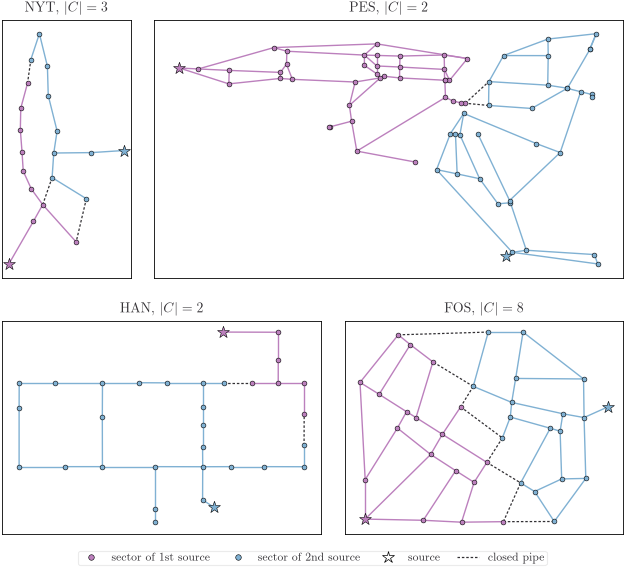

In [5]:
fig, axes = plot.instance_axes(nets)
for name, ax in axes.items():
    plot.sector_map(ax, nets[name], secs[name])
    plot.frame(ax, f'{name}, $|C|={len(secs[name]["closed"])}$')
plot.sector_legend(fig)
plot.save(fig, 'sectors')
plt.show()

## Complexity
With a binary heap and lazy deletion, one Dijkstra run costs $O((V+E)\log V)$ time and $O(V+E)$ space. Repeating it from each source costs $O(|S|(V+E)\log V)$ plus $O(|S|V)$ for the argmin; multi-source Dijkstra costs $O((V+E)\log V)$ independently of $|S|$. Finding $C$ is one $O(E)$ pass.

## Interpretation
Each sector is the service area its source would supply if the network were operated as independent districts. The number of pipes to close reflects how meshed the network is near the sector boundary: two or three closures suffice in the tree-like NYT and HAN and in PES, whose two clusters meet in a narrow band, while the FOS mesh needs eight. In HAN the sectors are very unequal (7 nodes against 25) because source 13 sits at the end of a long branch, so most of the network is closer to source 1. These sectors feed task 4 (farthest node per sector) and task 5 (flow inside each sector).